# Diverging Stacked Bar (Likert)

**Family:** Deviation &nbsp;|&nbsp; **Library:** matplotlib / seaborn &nbsp;|&nbsp; **Level:** Intermediate

> *Deviation:* Emphasise variations (+/-) from a fixed reference point: zero, a target, or an average.

## Design purpose

Stacks survey response levels so negative answers extend left and positive answers extend right from a central neutral line. Overall sentiment and its composition show together.

## When to use

- Show Likert-scale survey results (disagree ↔ agree)
- Compare sentiment across many questions or groups at a glance
- Show ordered categorical responses that have a natural midpoint

## Avoid when

- Responses are not ordered or have no natural neutral point
- Readers need exact values for the inner segments (use a table)
- There are more than 5–7 response levels

## Alternatives

- 100% stacked bar
- Small-multiple bar charts per question

## Design tips

- Split the neutral category half left, half right of the center line
- Use a diverging palette: two hues fading to a gray neutral
- Sort questions by net agreement

## Example

Employee engagement survey with five questions on a 5-point agreement scale.

### Setup

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

### Data

In [2]:
levels = ["Strongly disagree", "Disagree", "Neutral", "Agree", "Strongly agree"]
questions = ["I feel valued", "Workload is manageable", "Clear career path",
             "Good team communication", "Would recommend employer"]
pct = np.array([[5, 12, 20, 40, 23],
                [14, 26, 22, 28, 10],
                [18, 30, 25, 19, 8],
                [3, 8, 15, 45, 29],
                [6, 14, 24, 35, 21]], dtype=float)
df = pd.DataFrame(pct, index=questions, columns=levels)
df = df.loc[(df["Agree"] + df["Strongly agree"]).sort_values().index]
df

,Strongly disagree,Disagree,Neutral,Agree,Strongly agree
Clear career path,18.0,30.0,25.0,19.0,8.0
Workload is manageable,14.0,26.0,22.0,28.0,10.0
Would recommend employer,6.0,14.0,24.0,35.0,21.0
I feel valued,5.0,12.0,20.0,40.0,23.0
Good team communication,3.0,8.0,15.0,45.0,29.0


### Plot

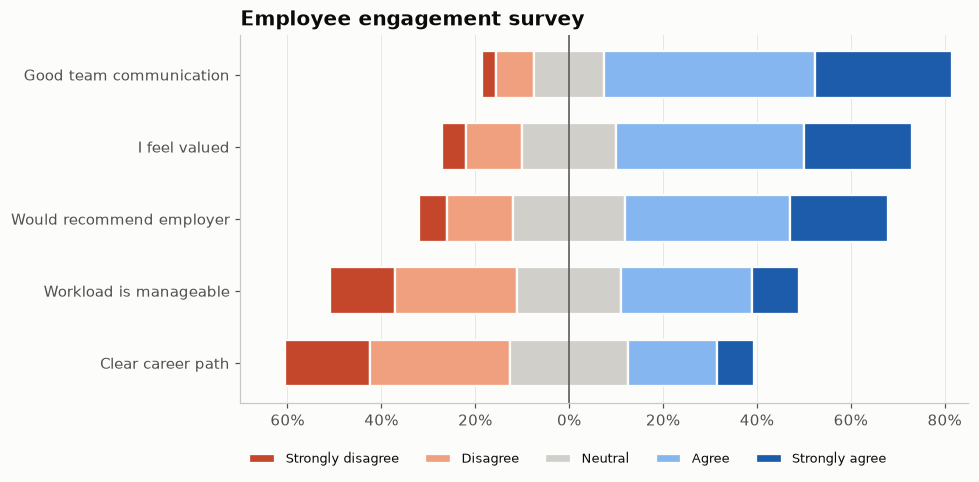

In [3]:
colors = ["#c4462b", "#f0a07f", "#d0cfca", "#86b6ef", "#1c5cab"]
left_start = -(df.iloc[:, 0] + df.iloc[:, 1] + df.iloc[:, 2] / 2)
fig, ax = plt.subplots(figsize=(9, 4.5))
left = left_start.values.copy()
for level, color in zip(df.columns, colors):
    ax.barh(df.index, df[level], left=left, color=color, label=level,
            height=0.65, edgecolor="#fcfcfb", linewidth=1.5)
    left += df[level].values
ax.axvline(0, color="#52514e", linewidth=1)
ax.set_xlim(-70, 85)
ax.set_xticks(range(-60, 81, 20))
ax.set_xticklabels([f"{abs(t)}%" for t in range(-60, 81, 20)])
ax.grid(axis="y", visible=False)
ax.set_title("Employee engagement survey")
ax.legend(ncol=5, loc="upper center", bbox_to_anchor=(0.45, -0.1), fontsize=8.5)
fig.tight_layout()
plt.show()

## How to read it

The share of each bar right of center is agreement and left of center is disagreement. Questions near the top have the most net agreement.

---
Standalone script: [`diverging_stacked_bar.py`](diverging_stacked_bar.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)